# Abi Farraj et al.- WQT Markets - Fig. 1

In [11]:
file = 'Figures/'

# import data

import pandas as pd
import os
import numpy as np

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag, WWTPs):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                if 'results' not in file:
                    continue
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if WWTP not in WWTPs:
                    continue
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_' + tag + '_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs
                    

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    
    return df


def create_df_finance_econ(path, WWTPs):
    df_all_WWTPs = pd.DataFrame()
    for WWTP in WWTPs:
        path_finance = path + f'results_finance_{WWTP}.csv'
        path_econ = path + f'results_econ_{WWTP}.csv'
        df_finance = pd.read_csv(path_finance, index_col=0)
        df_finance = df_finance.reset_index().rename(columns={"index": "Year"})
        df_econ = pd.read_csv(path_econ, index_col=0)
        df_econ = df_econ.reset_index().rename(columns={"index": "Year"})
        
        # merge but only keep duplicate data from left
        df_w = pd.merge(df_econ, df_finance, on="Year", how="left", suffixes=('_NPV', '_finance'))
        df_w['WWTP'] = WWTP
        df_all_WWTPs = pd.concat([df_all_WWTPs, df_w], axis=0)

    return df_all_WWTPs

def change_dict_to_df(data_dict, column):
    df_credit = pd.DataFrame.from_dict(data_dict, orient='index', columns=column)
    df_credit = df_credit.reset_index()
    df_credit[['WWTP', 'Year']] = pd.DataFrame(df_credit['index'].tolist(), index=df_credit.index)
    df_credit = df_credit.drop(columns=['index'])
    # only show years from 10 to 30
    df_credit = df_credit[df_credit['Year'] >= 10]
    df_credit = df_credit[df_credit['Year'] <= 29]
    return df_credit

## Calculate value of trade for each plant

In [12]:
path_NC = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/No_coordination/'
path_FC = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
path_bilat = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
path_HP_pt1_TR_1 = 'Results/Sensitivity_maxCredit_centralized_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/0.1/'
path_HP_0_TR_2 = 'Results/Sensitivity_maxCredit_centralized_market_TR_2.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'

WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']
Ls = ['SS', 'L2', 'L2upg3', 'L3']


df_NC = create_df_finance_econ(path_NC, WWTPs)
df_FC = create_df_finance_econ(path_FC, WWTPs)
df_bilat = create_df_finance_econ(path_bilat, WWTPs)
df_HP_pt1_TR_1 = create_df_finance_econ(path_HP_pt1_TR_1, WWTPs)
df_HP_0_TR_2 = create_df_finance_econ(path_HP_0_TR_2, WWTPs)

df_NC_results = create_dataframe(path_NC, 'results', WWTPs)
df_FC_results = create_dataframe(path_FC, 'results', WWTPs)
df_bilat_results = create_dataframe(path_bilat, 'results', WWTPs)
df_HP_pt1_TR_1_results = create_dataframe(path_HP_pt1_TR_1, 'results', WWTPs)
df_HP_0_TR_2_results = create_dataframe(path_HP_0_TR_2, 'results', WWTPs)
                                       

years = df_NC.index.unique()

# Bar graph of total investments and annual compliance costs

/var/folders/c4/xftw48qx1ln6q3hxvkc80tdw0000gn/T/ipykernel_3246/216596926.py:135: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  sns.boxplot(
/var/folders/c4/xftw48qx1ln6q3hxvkc80tdw0000gn/T/ipykernel_3246/216596926.py:203: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels(label_x, **hfont)
/var/folders/c4/xftw48qx1ln6q3hxvkc80tdw0000gn/T/ipykernel_3246/216596926.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Average cost for Bilateral_cost_per_lbN: $13.38 per lb N removed
Average cost for FC_cost_per_lbN: $10.56 per lb N removed
Average cost for NC_cost_per_lbN: $14.29 per lb N removed


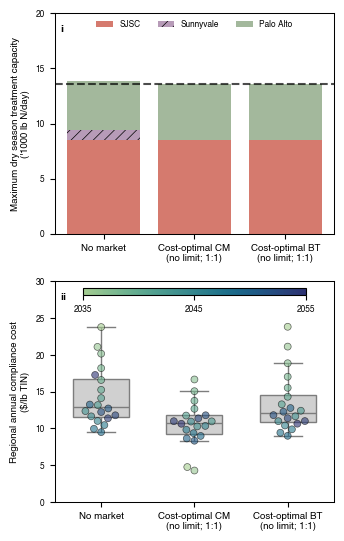

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
#colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#DD3E2C', 'Palo Alto': '#A3B89C'}
hatches_WWTP = {'Sunnyvale': '///', 'SJSC': '', 'Palo Alto': ''}
Ls = ['SS', 'L2', 'L2upg3', 'L3']
custom_colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
fontsize_lab = 6
leg_size = 6
lab_size = 6
line_wid = 0.75
bord_wid = 2
plt.rcParams['hatch.linewidth'] = 0.5

y_base = 1
ciel = -(len(WWTPs)//-2)-1

WWTP = 'Palo Alto'



fig, axs = plt.subplots(2, 1, figsize=(90/25.4, 140/25.4))  

max_dry_season_cap_NC = {}
max_dry_season_cap_FC = {}
max_dry_season_cap_bilat = {}
max_dry_season_cap_HP_pt1_TR_1 = {}
max_dry_season_cap_HP_0_TR_2 = {}
required_removal = {}
year = 2054
label_x = ['No market', 'Cost-optimal CM\n(no limit; 1:1)', 'Cost-optimal BT\n(no limit; 1:1)']

bottom_NC = 0
bottom_FC = 0
bottom_bilat = 0


for WWTP in WWTPs:

    df_NC_year = df_NC[df_NC['WWTP'] == WWTP]
    df_FC_year = df_FC[df_FC['WWTP'] == WWTP]
    df_bilat_year = df_bilat[df_bilat['WWTP'] == WWTP]

    df_NC_w = create_df(WWTP, df_NC_results)
    df_FC_w = create_df(WWTP, df_FC_results)
    df_bilat_w = create_df(WWTP, df_bilat_results)
    
    
    max_dry_season_cap_NC[WWTP] = max(df_NC_w['WWTP_x_cap_lim_COMPLIANCE']) * 0.001
    max_dry_season_cap_FC[WWTP] = max(df_FC_w['WWTP_x_cap_lim_COMPLIANCE']) * 0.001
    max_dry_season_cap_bilat[WWTP] = max(df_bilat_w['WWTP_x_cap_lim_COMPLIANCE']) * 0.001
    

    required_removal[WWTP] = max(df_NC_w['Required_removal']) * 0.001

    axs[0].bar(
        label_x,
        [max_dry_season_cap_NC[WWTP], max_dry_season_cap_FC[WWTP], max_dry_season_cap_bilat[WWTP]],
        color=colors_WWTP[WWTP],
        hatch=hatches_WWTP[WWTP],
        label=WWTP,
        bottom=[bottom_NC, bottom_FC, bottom_bilat],
    )

    # Update cumulative bottoms
    bottom_NC += max_dry_season_cap_NC[WWTP]
    bottom_FC += max_dry_season_cap_FC[WWTP]
    bottom_bilat += max_dry_season_cap_bilat[WWTP]

    
#axs[0].bar(label_x, [sum(required_removal.values())]*2, color='none', edgecolor='black', linestyle='--', linewidth=1.5, label='Required removal', alpha=0.7)
axs[0].axhline(y=sum(required_removal.values()), color='black', linestyle='--', linewidth=1.5, label='', alpha=0.7)


handles, labels = axs[0].get_legend_handles_labels()


axs[0].legend(loc='center', prop={'family':'Helvetica', 'size':lab_size}, frameon=False, bbox_to_anchor=(0.5, 0.95), ncol=3)


axs[0].set_ylim(0, 20)
axs[0].set_yticks(np.arange(0, 21, 5))
axs[0].set_ylabel("Maximum dry season treatment capacity\n('1000 lb N/day)", **hfont)

#axs[0].set_xlabel('')
#axs[0].set_xticks([0, 1, 2, 3, 4])
#axs[0].set_xticklabels(label_x, **hfont)
axs[0].set_xticklabels([])


# plot average compliance cost ($/lb N removed) for NC and FC
df_regional_costs = pd.DataFrame()
df_regional_costs['Datetime'] = df_NC['Year']
df_regional_costs['Year'] = pd.to_datetime(df_NC['Year']).dt.year
df_regional_costs['WWTP'] = df_NC['WWTP']

df_regional_costs['Required_removal'] = df_NC['Required_removal']
df_regional_costs['NC_total_costs'] = df_NC['Annual_capex'] + df_NC['Annual_opex']
df_regional_costs['FC_total_costs'] = df_FC['Annual_capex'] + df_FC['Annual_opex']
df_regional_costs['Bilateral_total_costs'] = df_bilat['Annual_capex'] + df_bilat['Annual_opex']


# sum df_regional_costs by year
df_regional_costs_total = df_regional_costs.groupby('Year').sum().reset_index()

#calculate cost per lb N removed for each row unless required removal is zero
df_regional_costs_total['NC_cost_per_lbN'] = np.where(df_regional_costs_total['Required_removal'] > 0,
                                                       df_regional_costs_total['NC_total_costs'] / df_regional_costs_total['Required_removal']* (10**6 / 30), np.nan)
df_regional_costs_total['FC_cost_per_lbN'] = np.where(df_regional_costs_total['Required_removal'] > 0,
                                                       df_regional_costs_total['FC_total_costs'] / df_regional_costs_total['Required_removal']* (10**6 / 30), np.nan)
df_regional_costs_total['Bilateral_cost_per_lbN'] = np.where(df_regional_costs_total['Required_removal'] > 0,
                                                       df_regional_costs_total['Bilateral_total_costs'] / df_regional_costs_total['Required_removal']* (10**6 / 30), np.nan)
    


df_long = df_regional_costs_total.melt(
    id_vars=['Year'], 
    value_vars=['NC_cost_per_lbN', 'FC_cost_per_lbN', 'Bilateral_cost_per_lbN'],
    var_name='Category', 
    value_name='Cost'
        ).dropna()

df_long['Year'] = pd.to_numeric(df_long['Year'])
#sns.swarmplot(data=data_to_plot, color='k', size=4, ax=axs[1], alpha=0.3)
#sns.violinplot(data=data_to_plot, palette=['#A3B89C', '#726DA8'], ax=axs[1])

sns.boxplot(
    data=df_long, 
    x='Category', 
    y='Cost',
    hue='Category',
    palette=['#D0D0D0', '#D0D0D0', '#D0D0D0', '#D0D0D0', '#D0D0D0'], 
    ax=axs[1], 
    width=0.6, 
    showfliers=False,
    legend=False
)

sns.swarmplot(
    data=df_long, 
    x='Category', 
    y='Cost', 
    hue='Year',
    palette='crest',  # or any colormap you prefer
    size=5, 
    linewidth=0.5,
    edgecolor='k',
    ax=axs[1], 
    alpha=0.6,
    legend = False
)

axs[1].set_xlabel('')

# add average unit cost under each subplot
avg_costs = df_long.groupby('Category')['Cost'].mean().reset_index()
avg_costs_dict = dict(zip(avg_costs['Category'], avg_costs['Cost']))
for i, category in enumerate(avg_costs['Category']):
    avg_cost = avg_costs_dict[category]
    print(f"Average cost for {category}: ${avg_cost:.2f} per lb N removed")

# Add a continuous colorbar instead
norm = plt.Normalize(vmin=2035, vmax=2055)
sm = plt.cm.ScalarMappable(cmap='crest', norm=norm)
sm.set_array([])

# Create inset axes for colorbar (adjust position and size as needed)
cax = inset_axes(axs[1], width="80%", height="3%", loc='upper center',
                 bbox_to_anchor=(0, 0.05, 1, 0.95), bbox_transform=axs[1].transAxes)
cbar = plt.colorbar(sm, cax=cax, orientation='horizontal')
cbar.set_ticks([2035, 2045, 2055])
#cbar.set_label('Year', fontsize=9)
cbar.ax.tick_params(labelsize=fontsize_lab)
for label in cbar.ax.get_xticklabels():
    label.set_fontname('Helvetica')



axs[1].set_xticks([0, 1, 2])
axs[1].set_ylim(0, 30)
axs[1].set_yticks(np.arange(0, 31, 5))
axs[1].set_yticklabels(np.arange(0, 31, 5), **hfont_ticks)
axs[1].set_ylabel('Regional annual compliance cost\n($/lb TIN)', **hfont)



fig_labels = ['i', 'ii']
for i,ax in enumerate(axs):
    ax.text(0.02, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=lab_size, fontweight='bold', va='top', ha='left')
    axs[i].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
    axs[i].xaxis.set_ticks_position('bottom')
    for spine in axs[i].spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
axs[1].set_xticklabels(label_x, **hfont)
axs[0].set_xticklabels(label_x, **hfont)

fig.tight_layout()
name = '/Fig_1a'
fig.savefig(file + name + ".svg", format="svg", dpi=300) 

In [14]:
#results_trade_by_WWTP
df_NC_results_trade = create_dataframe(path_NC, 'trade_by_WWTP', WWTPs)
df_FC_results_trade = create_dataframe(path_FC, 'trade_by_WWTP', WWTPs)
df_bilat_results_trade = create_dataframe(path_bilat, 'trade_by_WWTP', WWTPs)
df_HP_pt1_TR_1_results_trade = create_dataframe(path_HP_pt1_TR_1, 'trade_by_WWTP', WWTPs)
df_HP_0_TR_2_results_trade = create_dataframe(path_HP_0_TR_2, 'trade_by_WWTP', WWTPs)

Cost-optimal CM
(no limits; 1:1)
     Total volume bought: 2470.2366488173675
     Required removal: 857365 lb/day
     CoC compliance cost: 271 $mil
     Unit CoC: 10.53 $/lb TIN
     Total available: 3026 lbs
Cost-optimal BT
(no limits; 1:1)
     Total volume bought: 945.9268397398355
     Required removal: 857365 lb/day
     CoC compliance cost: 317 $mil
     Unit CoC: 12.31 $/lb TIN
     Total available: 6738 lbs


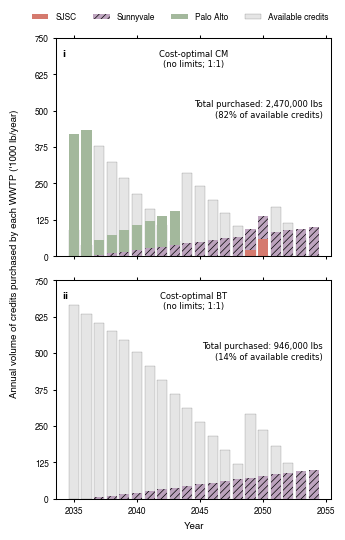

In [15]:
import matplotlib.pyplot as plt

WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}
hatches_WWTP = {'Sunnyvale': '/////', 'SJSC': '', 'Palo Alto': ''}
#colors_WWTP = {'Sunnyvale': '#B455B7', 'SJSC': '#DD3E2C', 'Palo Alto': '#A3B89C'}
colors = {'L3':'black', 'L2':'red', 'L2upg3':'green', 'SS': 'pink'}
colors_traded = ['#C4C8B8', '#627437']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
lab_size = 6
line_wid = 0.75
bord_wid = 2

label_x = ['Cost-optimal CM\n(no limits; 1:1)', 'Cost-optimal BT\n(no limits; 1:1)']
dfs = [df_FC_results_trade, df_bilat_results_trade]
dfs_finance_econ = [df_FC, df_bilat]

TRs = [1.0, 1.0]

fig, axs = plt.subplots(len(label_x), 1, figsize=(90/25.4, 140/25.4))
ciel = -(len(label_x)//-2)-1

total_treated_for_trade_str = {}
total_credits_bought = {}
total_available = {}
volume_bought_dict = {}
volume_sold_dict = {}
total_dry_season_capacity = {}
total_treated = {}
total_treated_for_permit_dict = {}
total_treated_for_trade_dict = {}
avg_credit_price = {}

for i, market in enumerate(label_x):
    
    df_i = dfs[i]
    df_finance_econ = dfs_finance_econ[i]
    df_finance_econ['years'] = pd.to_datetime(df_finance_econ.Year).dt.year
    df_finance_econ = df_finance_econ[(df_finance_econ['years'] >= 2035) & (df_finance_econ['years'] < 2055)]
    
    for WWTP in WWTPs:
        df = create_df(WWTP, df_i)
        df_finance_econ_w = df_finance_econ[df_finance_econ['WWTP'] == WWTP]
        df['years'] = pd.to_datetime(df.Datetime).dt.year
        df = df[(df['years'] >= 2035) & (df['years'] < 2055)]
        
        volume_sold_dict[WWTP] = df.groupby('years')['Total_sold'].sum()*30 / 1000
        volume_bought_dict[WWTP] = df.groupby('years')['Total_bought'].sum()*30 / 1000
        total_dry_season_capacity[WWTP] = df_finance_econ_w['Total_Dry_Season_Capacity']* 30 / 1000
        total_treated[WWTP] = df_finance_econ_w['Annual_treated']* 30 / 1000
        #total_treated_for_trade_dict[WWTP] = df.groupby('years')['Total_credits_treated'].sum()*30 / 1000
        #total_treated_for_permit_dict[WWTP] = df.groupby('years')['Total_treated'].sum()*30 / 1000 - total_treated_for_trade_dict[WWTP]
        
    total_bought_theoretical = (sum(total_dry_season_capacity[WWTP] for WWTP in WWTPs) - sum(total_treated[WWTP] for WWTP in WWTPs))/ TRs[i]
    required_removal = (df_finance_econ.Required_removal).sum()
    CoC_compliance = (df_finance_econ['Annual_capex'] + df_finance_econ['Annual_opex']).sum()
    CoC_unit_CoC = (CoC_compliance / required_removal) * (10**6 /30)
    
    
    #required_removal = df.groupby('years')['Required_removal'].sum() / 1000
    # dashed bars for required removal
    if 'CM' in market:
        WWTPs_market = WWTPs
    else:
        WWTPs_market = ['Palo Alto', 'Sunnyvale']
    
    total_volume_bought = sum(volume_bought_dict[WWTP] for WWTP in WWTPs)
    #total_treated_for_permit = sum(total_treated_for_permit_dict[WWTP] for WWTP in WWTPs)
    #total_treated_for_trade = sum(total_treated_for_trade_dict[WWTP] for WWTP in WWTPs)

    axs[i].bar(df.years.unique(), volume_bought_dict['SJSC'], color = colors_WWTP['SJSC'], hatch = hatches_WWTP['SJSC'], label = 'SJSC', linewidth = line_wid)
    axs[i].bar(df.years.unique(), volume_bought_dict['Sunnyvale'], color = colors_WWTP['Sunnyvale'], hatch = hatches_WWTP['Sunnyvale'], label = 'Sunnyvale', linewidth = line_wid, alpha=0.9, bottom = volume_bought_dict['SJSC'])
    axs[i].bar(df.years.unique(), volume_bought_dict['Palo Alto'], color = colors_WWTP['Palo Alto'], hatch = hatches_WWTP['Palo Alto'], label = 'Palo Alto', linewidth = line_wid, bottom = volume_bought_dict['SJSC'] + volume_bought_dict['Sunnyvale'])
    axs[i].bar(df.years.unique(), total_bought_theoretical, color = 'black', edgecolor = 'black', linestyle = '-', linewidth = 0.1, label = 'Available credits', facecolor=(0, 0, 0, 0.1), zorder = 0)
    
    
    
    #str_1 = "Total volume purchased:\n"
    str_1 = "Total purchased: "
    str_2 = "% of available credits)"

    
    total_credits_bought[i] = f"{str_1}{int(round(total_volume_bought.sum())*1000):,} lbs"
    total_available[i] = f"({round(total_volume_bought.sum() / total_bought_theoretical.sum() * 100)}{str_2}"
    avg_credit_price[i] = f"Avg. cost: {round(CoC_unit_CoC.sum(),1):,} $/lb"
    
    print(market)
    print('     Total volume bought: ' + str(total_volume_bought.sum()))
    print('     Required removal: ' + str(round(required_removal)) + ' lb/day')
    print('     CoC compliance cost: ' + str(round(CoC_compliance)) + ' $mil')
    print('     Unit CoC: ' + str(round(CoC_unit_CoC,2)) + ' $/lb TIN')
    print('     Total available: ' + str(round(total_bought_theoretical.sum())) + ' lbs')
    

    y_max = 750
    y_space = 125

    axs[i].set_ylim(0, y_max)
    axs[i].set_yticks(np.arange(0, y_max + 1, y_space))
    axs[i].set_yticklabels(np.arange(0, y_max + 1, y_space), **hfont_ticks)
    axs[i].set_xticks([2035, 2040, 2045, 2050, 2055])
    axs[i].set_xticklabels([2035, 2040, 2045, 2050, 2055], rotation=0, **hfont_ticks)
    if i != len(label_x)-1:
        axs[i].set_xticklabels([])
    else:
        axs[i].set_xlabel('Year', **hfont)
        #axs[i].set_xticklabels(df.years.unique(), rotation=0, **hfont_ticks)
    axs[i].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
    
    
    



#axs[3].legend(loc='upper left', prop={'family':'Helvetica', 'size':lab_size}, frameon=False, bbox_to_anchor=(0.1, 0.98))
axs[0].legend(loc='upper center', prop={'family':'Helvetica', 'size':lab_size}, frameon=False, bbox_to_anchor=(0.45, 1.15), ncol=4)
fig_labels = ['i', 'ii', 'iii', 'iv']
for i,ax in enumerate(axs):
    ax.text(0.97, 0.7, total_credits_bought[i], transform=ax.transAxes, fontsize=lab_size, va='center', ha='right', color = 'black')
    ax.text(0.97, 0.65, total_available[i], transform=ax.transAxes, fontsize=lab_size, va='center', ha='right', color = 'black')
    #ax.text(0.97, 0.45, avg_credit_price[i], transform=ax.transAxes, fontsize=lab_size, va='center', ha='right', color = 'black')
    ax.text(0.5, 0.95, label_x[i], transform=ax.transAxes, fontsize=lab_size, va='top', ha='center')
    ax.text(0.02, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=lab_size, fontweight='bold', va='top', ha='left')
    ax.xaxis.set_ticks_position('both')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=lab_size)
    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    
y_label_text = "Annual volume of credits purchased by each WWTP ('1000 lb/year)"
fig.tight_layout()    
fig.supylabel(y_label_text, **hfont, x=0.04, y = 0.53)
fig.tight_layout()    

name = '/Fig_1b'
fig.savefig(file + name + ".svg", format="svg", dpi=300) 
